# TIL-AI CV YOLO Full Multi-Model Training Notebook

Workflow:
1. Load dataset
2. Convert COCO annotations to YOLO format
3. Create train/validation split
4. Train multiple YOLO models
5. Collect accuracy metrics
6. Benchmark prediction speed
7. Compare mAP + FPS
8. Choose best tradeoff model
9. Run prediction using selected best model

Run from top to bottom.

In [1]:
!pip install opencv-python matplotlib pandas tqdm
!pip install requests
!pip install kaggle kagglehub

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 72.9/72.9 MB 112.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.8/8.8 MB 168.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 11.3/11.3 MB 147.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.1/5.1 MB 182.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.4/1.4 MB 208.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.9/16.9 MB 153.4 MB/s eta 0:00:00
  Attempting uninstall: pyparsing
    Found existing installation: pyparsing 2.4.7
    Uninstalling pyparsing-2.4.7:
      Successfully uninstalled pyparsing-2.4.7
  Attempting uninstall: numpy
    Found existing installation: numpy 1.26.3
    Uninstalling numpy-1.26.3:
      Successfully uninstalled numpy-1.26.3

[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip

[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, 

In [2]:
# Imports and paths
import json
import random
import shutil
import time
from tqdm import tqdm
from collections import Counter, defaultdict
from pathlib import Path
import requests

import cv2
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import numpy as np
import pandas as pd
import yaml
from PIL import Image
from tqdm.auto import tqdm
import kagglehub


import os

os.environ["KAGGLE_USERNAME"] = "maureenkichor"
os.environ["KAGGLE_KEY"] = "KGAT_7bba67cba0ca30d80ac89c653a150d36"

# 2. Download using the precise canonical slug discovered from the API response
print("Downloading advanced/cv dataset (~4.7 GB)... This may take a few minutes.")
try:
    downloaded_path = kagglehub.dataset_download("wongpohyee/advancedcv")
    print(f"✓ Dataset downloaded and extracted to: {downloaded_path}")
    
    # 3. Create the symbolic link so your downstream Computer Vision code works perfectly
    runpod_target = Path("/workspace/advanced/cv")
    runpod_target.parent.mkdir(parents=True, exist_ok=True)

    if not runpod_target.exists():
        os.symlink(downloaded_path, runpod_target)
        print(f"✓ Shortcut created at: {runpod_target}")
    else:
        print(f"ℹ Note: {runpod_target} already exists.")

    # 4. Verify the unzipped files are readable
    print("\nVerifying files inside /workspace/advanced/cv:")
    !find /workspace/advanced/cv | head

except Exception as e:
    print(f"\n✗ Download failed: {e}")

100%|██████████| 4.43G/4.43G [01:56<00:00, 41.0MB/s]

Extracting files...


✓ Dataset downloaded and extracted to: /root/.cache/kagglehub/datasets/wongpohyee/advancedcv/versions/1
✓ Shortcut created at: /workspace/advanced/cv

Verifying files inside /workspace/advanced/cv:
/workspace/advanced/cv


In [3]:
# Input dataset path
BASE_PATH = Path("/workspace/advanced/cv/cv")
IMAGES_DIR = BASE_PATH / "images"
ANNOTATION_PATH = BASE_PATH / "annotations.json"

# Working/output path
OUTPUT_PATH = Path("/workspace/yolo")
LABELS_DIR = OUTPUT_PATH / "labels"
TRAIN_IMG_DIR = OUTPUT_PATH / "train/images"
VAL_IMG_DIR = OUTPUT_PATH / "val/images"
TRAIN_LBL_DIR = OUTPUT_PATH / "train/labels"
VAL_LBL_DIR = OUTPUT_PATH / "val/labels"
DATA_YAML = OUTPUT_PATH / "data.yaml"

RUNS_DIR = Path("/workspace/runs/detect")
PREDICT_DIR = Path("/workspace/predict")
BENCHMARK_DIR = OUTPUT_PATH / "benchmark"
NOISY_VAL_DIR = OUTPUT_PATH / "val_noisy"

print("BASE_PATH exists:", BASE_PATH.exists())
print("IMAGES_DIR exists:", IMAGES_DIR.exists())
print("ANNOTATION_PATH exists:", ANNOTATION_PATH.exists())

# Load annotations
with open(ANNOTATION_PATH, "r") as f:
    data = json.load(f)

print("Top-level keys:", data.keys())
print("Images:", len(data["images"]))
print("Annotations:", len(data["annotations"]))
print("Categories:", len(data["categories"]))

categories = sorted(data["categories"], key=lambda x: x["id"])
cat_map = {c["id"]: c["name"] for c in categories}
cat_id_to_idx = {cat_id: idx for idx, cat_id in enumerate(cat_map.keys())}
class_names = [cat_map[cat_id] for cat_id in cat_map.keys()]

print("Class names:")
for i, name in enumerate(class_names):
    print(i, name)

BASE_PATH exists: True
IMAGES_DIR exists: True
ANNOTATION_PATH exists: True
Top-level keys: dict_keys(['info', 'images', 'annotations', 'licenses', 'categories'])
Images: 5000
Annotations: 19392
Categories: 18
Class names:
0 cargo aircraft
1 commercial aircraft
2 drone
3 fighter jet
4 fighter plane
5 helicopter
6 light aircraft
7 missile
8 truck
9 car
10 tank
11 bus
12 van
13 cargo ship
14 yacht
15 cruise ship
16 warship
17 sailboat


In [4]:
# Dataset check
counts = Counter(ann["category_id"] for ann in data["annotations"])

rows = []
for cat_id, count in sorted(counts.items()):
    rows.append({
        "category_id": cat_id,
        "yolo_class_id": cat_id_to_idx[cat_id],
        "class_name": cat_map[cat_id],
        "annotation_count": count
    })

df_class_counts = pd.DataFrame(rows)
df_class_counts

,category_id,yolo_class_id,class_name,annotation_count
0,0,0,cargo aircraft,292
1,1,1,commercial aircraft,1703
2,2,2,drone,941
3,3,3,fighter jet,2515
4,4,4,fighter plane,1207
5,5,5,helicopter,1597
6,6,6,light aircraft,910
7,7,7,missile,805
8,8,8,truck,2353
9,9,9,car,983


Found: /workspace/advanced/cv/cv/images/3235.jpg


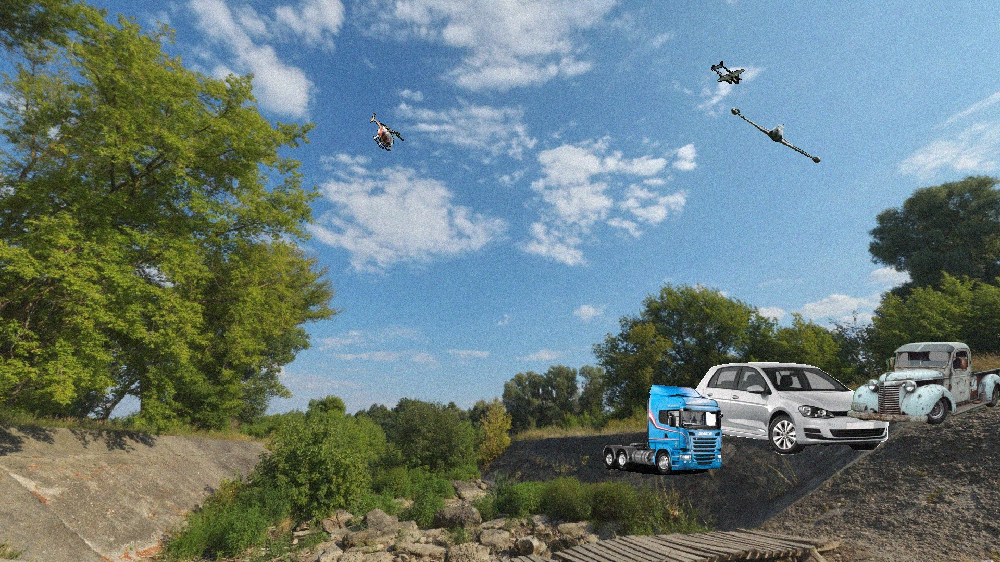

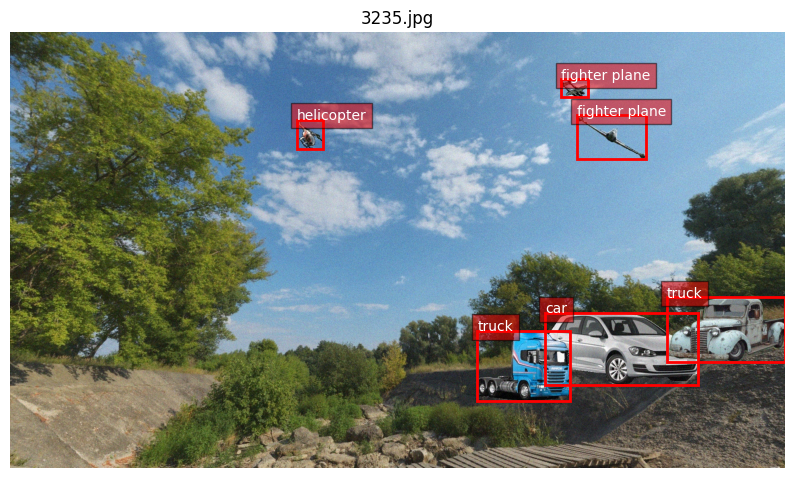

In [5]:
# Preview one labelled image
for img_info in data["images"]:
    img_path = IMAGES_DIR / Path(img_info["file_name"]).name

    if img_path.exists():
        print("Found:", img_path)

        img = Image.open(img_path)
        display(img)

        image_id = img_info["id"]
        break
else:
    print("No matching images found")
anns = [a for a in data["annotations"] if a["image_id"] == image_id]

fig, ax = plt.subplots(figsize=(10, 8))
ax.imshow(img)

for ann in anns:
    x, y, w, h = ann["bbox"]
    rect = patches.Rectangle((x, y), w, h, linewidth=2, edgecolor="red", facecolor="none")
    ax.add_patch(rect)
    ax.text(x, y, cat_map[ann["category_id"]], color="white", fontsize=10, bbox=dict(facecolor="red", alpha=0.5))

ax.set_title(img_info["file_name"])
ax.axis("off")
plt.show()

In [6]:
# Convert COCO annotations to YOLO labels
LABELS_DIR.mkdir(parents=True, exist_ok=True)

image_to_anns = defaultdict(list)
for ann in data["annotations"]:
    image_to_anns[ann["image_id"]].append(ann)

for img_info in tqdm(data["images"], desc="Converting labels"):
    img_id = img_info["id"]
    img_w = img_info["width"]
    img_h = img_info["height"]
    stem = Path(img_info["file_name"]).stem
    label_path = LABELS_DIR / f"{stem}.txt"

    lines = []
    for ann in image_to_anns[img_id]:
        x, y, w, h = ann["bbox"]

        x_center = (x + w / 2) / img_w
        y_center = (y + h / 2) / img_h
        norm_w = w / img_w
        norm_h = h / img_h

        class_id = cat_id_to_idx[ann["category_id"]]
        lines.append(f"{class_id} {x_center:.6f} {y_center:.6f} {norm_w:.6f} {norm_h:.6f}")

    label_path.write_text("\n".join(lines))

print("Labels saved to:", LABELS_DIR)
print("Example label files:", list(LABELS_DIR.glob("*.txt"))[:5])

Converting labels:   0%|          | 0/5000 [00:00<?, ?it/s]

Labels saved to: /workspace/yolo/labels
Example label files: [PosixPath('/workspace/yolo/labels/951.txt'), PosixPath('/workspace/yolo/labels/2211.txt'), PosixPath('/workspace/yolo/labels/270.txt'), PosixPath('/workspace/yolo/labels/3127.txt'), PosixPath('/workspace/yolo/labels/3885.txt')]


In [7]:
# delete generated output files if rerun
import shutil

shutil.rmtree(TRAIN_IMG_DIR, ignore_errors=True)
shutil.rmtree(VAL_IMG_DIR, ignore_errors=True)
shutil.rmtree(TRAIN_LBL_DIR, ignore_errors=True)
shutil.rmtree(VAL_LBL_DIR, ignore_errors=True)

print("Old split folders removed.")

Old split folders removed.


In [8]:
!pip install iterative-stratification
from iterstrat.ml_stratifiers import MultilabelStratifiedShuffleSplit

for d in [TRAIN_IMG_DIR, VAL_IMG_DIR, TRAIN_LBL_DIR, VAL_LBL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

images = sorted(
    list(IMAGES_DIR.glob("*.jpg")) +
    list(IMAGES_DIR.glob("*.jpeg")) +
    list(IMAGES_DIR.glob("*.png"))
)

# Build multilabel target for each image from YOLO label txt files
image_paths = []
multi_labels = []

for img_path in images:
    label_path = LABELS_DIR / f"{img_path.stem}.txt"

    if not label_path.exists():
        continue

    class_ids = set()

    with open(label_path, "r") as f:
        for line in f:
            parts = line.strip().split()
            if len(parts) >= 1:
                class_ids.add(int(parts[0]))

    label_vector = [0] * 18   # you have 18 classes: 0 to 17

    for cls_id in class_ids:
        label_vector[cls_id] = 1

    image_paths.append(img_path)
    multi_labels.append(label_vector)

X = np.array(image_paths)
y = np.array(multi_labels)

msss = MultilabelStratifiedShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, val_idx = next(msss.split(X, y))

train_images = X[train_idx]
val_images = X[val_idx]

def copy_image_and_label(img_path, img_dst_dir, lbl_dst_dir):
    dst_img = img_dst_dir / img_path.name
    if not dst_img.exists():
        shutil.copy2(img_path, dst_img)

    label_src = LABELS_DIR / f"{img_path.stem}.txt"
    label_dst = lbl_dst_dir / f"{img_path.stem}.txt"

    if label_src.exists() and not label_dst.exists():
        shutil.copy2(label_src, label_dst)

for img_path in tqdm(train_images, desc="Copy train"):
    copy_image_and_label(img_path, TRAIN_IMG_DIR, TRAIN_LBL_DIR)

for img_path in tqdm(val_images, desc="Copy val"):
    copy_image_and_label(img_path, VAL_IMG_DIR, VAL_LBL_DIR)

print("Train images:", len(list(TRAIN_IMG_DIR.glob("*"))))
print("Val images:", len(list(VAL_IMG_DIR.glob("*"))))

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 45.8 MB/s eta 0:00:00a 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 35.3/35.3 MB 201.8 MB/s eta 0:00:00

[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip


Copy train:   0%|          | 0/4000 [00:00<?, ?it/s]

Copy val:   0%|          | 0/1000 [00:00<?, ?it/s]

Train images: 4000
Val images: 1000


In [9]:
# Create data.yaml
OUTPUT_PATH.mkdir(parents=True, exist_ok=True)

yaml_content = {
    "path": str(OUTPUT_PATH),
    "train": "train/images",
    "val": "val/images",
    "nc": len(class_names),
    "names": class_names
}

with open(DATA_YAML, "w") as f:
    yaml.safe_dump(yaml_content, f, sort_keys=False)

print(DATA_YAML.read_text())

path: /workspace/yolo
train: train/images
val: val/images
nc: 18
names:
- cargo aircraft
- commercial aircraft
- drone
- fighter jet
- fighter plane
- helicopter
- light aircraft
- missile
- truck
- car
- tank
- bus
- van
- cargo ship
- yacht
- cruise ship
- warship
- sailboat



In [10]:
# Install YOLO
!pip install -q ultralytics

import os
import torch
from ultralytics import YOLO

GPU_DEVICE = 0
TRAIN_BATCH = 0.90  # Ultralytics AutoBatch target: use about 90% of GPU memory.
TRAIN_WORKERS = min(16, max(2, (os.cpu_count() or 2) - 2))

if not torch.cuda.is_available():
    raise RuntimeError("CUDA GPU is not available. Enable the A100 GPU before training.")

torch.cuda.set_device(GPU_DEVICE)
torch.backends.cudnn.benchmark = True
torch.backends.cuda.matmul.allow_tf32 = True
torch.backends.cudnn.allow_tf32 = True

try:
    torch.set_float32_matmul_precision("high")
except Exception:
    pass

gpu = torch.cuda.get_device_properties(GPU_DEVICE)
print("Ultralytics imported successfully")
print(f"Using GPU {GPU_DEVICE}: {gpu.name} ({gpu.total_memory / 1024**3:.1f} GB VRAM)")
print(f"Training batch setting: {TRAIN_BATCH} GPU-memory AutoBatch | dataloader workers: {TRAIN_WORKERS}")


[notice] A new release of pip is available: 24.2 -> 26.1.1
[notice] To update, run: python -m pip install --upgrade pip
Creating new Ultralytics Settings v0.0.6 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/quickstart/#ultralytics-settings.
Ultralytics imported successfully
Using GPU 0: NVIDIA A100-SXM4-80GB (79.3 GB VRAM)
Training batch setting: 0.9 GPU-memory AutoBatch | dataloader workers: 16


## Multi-model training

This section trains several models, validates them, measures prediction speed, and stores everything in one comparison table.

You can reduce `epochs` first for testing. For final result, use 30 to 50 epochs depending on Kaggle GPU time.

In [11]:
# Train multiple models + collect metrics + benchmark speed

experiments = [
    {"base_model": "yolov8n.pt", "imgsz": 640, "epochs": 30, "name": "yolov8n_640"},
    {"base_model": "yolov8n.pt", "imgsz": 960, "epochs": 30, "name": "yolov8n_960"},
    {"base_model": "yolov8s.pt", "imgsz": 640, "epochs": 30, "name": "yolov8s_640"},
    {"base_model": "yolov8s.pt", "imgsz": 960, "epochs": 30, "name": "yolov8s_960"},
    {"base_model": "yolov8m.pt", "imgsz": 640, "epochs": 30, "name": "yolov8m_640"},
    {"base_model": "yolov8m.pt", "imgsz": 960, "epochs": 30, "name": "yolov8m_960"},
]

results_list = []
val_image_count = len(list(VAL_IMG_DIR.glob("*")))

if 'BACKUP_DIR' not in locals() and 'BACKUP_DIR' not in globals():
    from pathlib import Path
    BACKUP_DIR = Path("/workspace/backups")
    BACKUP_DIR.mkdir(parents=True, exist_ok=True)

for exp in experiments:
    print("=" * 80)
    print(f"Training: {exp['name']}")
    print("=" * 80)

    model = YOLO(exp["base_model"])
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(GPU_DEVICE)

    train_result = model.train(
        data=str(DATA_YAML),
        epochs=exp["epochs"],
        imgsz=exp["imgsz"],
        batch=TRAIN_BATCH,
        patience=10,
        cache="ram",
        project=str(RUNS_DIR),
        name=exp["name"],
        exist_ok=True,
        device=GPU_DEVICE,
        workers=TRAIN_WORKERS,
        amp=True,
        verbose=True
    )
    peak_allocated_gb = torch.cuda.max_memory_allocated(GPU_DEVICE) / 1024**3
    peak_reserved_gb = torch.cuda.max_memory_reserved(GPU_DEVICE) / 1024**3
    print(f"GPU peak memory allocated: {peak_allocated_gb:.2f} GB | reserved: {peak_reserved_gb:.2f} GB")

    best_pt = RUNS_DIR / exp["name"] / "weights/best.pt"
    trained_model = YOLO(str(best_pt))
    
    # zip this model folder immediately after training
    model_folder = RUNS_DIR / exp["name"]
    backup_zip = BACKUP_DIR / f"{exp['name']}_backup"

    shutil.make_archive(str(backup_zip), "zip", root_dir=str(model_folder))

    print(f"Backup created: {backup_zip}.zip")
	
    print(f"Validating: {exp['name']}")
    metrics = trained_model.val(
        data=str(DATA_YAML),
        imgsz=exp["imgsz"],
        split="val",
        device=GPU_DEVICE,
        half=True,
        verbose=False
    )

    print(f"Benchmarking prediction speed: {exp['name']}")
    start = time.time()
    trained_model.predict(
        source=str(VAL_IMG_DIR),
        imgsz=exp["imgsz"],
        conf=0.25,
        save=False,
        device=GPU_DEVICE,
        half=True,
        verbose=False
    )
    end = time.time()

    total_predict_time = end - start
    fps = val_image_count / total_predict_time if total_predict_time > 0 else 0

    results_list.append({
        "model_name": exp["name"],
        "base_model": exp["base_model"],
        "imgsz": exp["imgsz"],
        "epochs": exp["epochs"],
        "mAP50": float(metrics.box.map50),
        "mAP50_95": float(metrics.box.map),
        "precision": float(metrics.box.mp),
        "recall": float(metrics.box.mr),
        "val_images": val_image_count,
        "total_predict_time_sec": total_predict_time,
        "fps": fps,
        "best_pt": str(best_pt)
    })

    df_partial = pd.DataFrame(results_list)
    display(df_partial.sort_values("mAP50_95", ascending=False))

df_results = pd.DataFrame(results_list)
df_results

Training: yolov8n_640
Ultralytics 8.4.53 🚀 Python-3.11.10 torch-2.4.1+cu124 CUDA:0 (NVIDIA A100-SXM4-80GB, 81156MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.9, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_640, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.60618,/workspace/runs/detect/yolov8n_640/weights/bes...


Training: yolov8n_960
Ultralytics 8.4.53 🚀 Python-3.11.10 torch-2.4.1+cu124 CUDA:0 (NVIDIA A100-SXM4-80GB, 81156MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.9, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8n_960, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
1,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.88004,/workspace/runs/detect/yolov8n_960/weights/bes...
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.60618,/workspace/runs/detect/yolov8n_640/weights/bes...


Training: yolov8s_640
Ultralytics 8.4.53 🚀 Python-3.11.10 torch-2.4.1+cu124 CUDA:0 (NVIDIA A100-SXM4-80GB, 81156MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.9, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8s.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8s_640, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
1,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.88004,/workspace/runs/detect/yolov8n_960/weights/bes...
2,yolov8s_640,yolov8s.pt,640,30,0.956690,0.864177,0.942387,0.910949,1000,49.228975,20.31324,/workspace/runs/detect/yolov8s_640/weights/bes...
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.60618,/workspace/runs/detect/yolov8n_640/weights/bes...


... (3 outputs left out)

,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
3,yolov8s_960,yolov8s.pt,960,30,0.991685,0.944604,0.990017,0.975664,1000,28.875689,34.631208,/workspace/runs/detect/yolov8s_960/weights/bes...
4,yolov8m_640,yolov8m.pt,640,30,0.985177,0.914747,0.975076,0.957930,1000,32.411978,30.852792,/workspace/runs/detect/yolov8m_640/weights/bes...
1,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.880040,/workspace/runs/detect/yolov8n_960/weights/bes...
2,yolov8s_640,yolov8s.pt,640,30,0.956690,0.864177,0.942387,0.910949,1000,49.228975,20.313240,/workspace/runs/detect/yolov8s_640/weights/bes...
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.606180,/workspace/runs/detect/yolov8n_640/weights/bes...


Training: yolov8m_960
Ultralytics 8.4.53 🚀 Python-3.11.10 torch-2.4.1+cu124 CUDA:0 (NVIDIA A100-SXM4-80GB, 81156MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.9, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=960, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8m_960, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
5,yolov8m_960,yolov8m.pt,960,30,0.994626,0.961373,0.994170,0.988327,1000,40.842219,24.484468,/workspace/runs/detect/yolov8m_960/weights/bes...
3,yolov8s_960,yolov8s.pt,960,30,0.991685,0.944604,0.990017,0.975664,1000,28.875689,34.631208,/workspace/runs/detect/yolov8s_960/weights/bes...
4,yolov8m_640,yolov8m.pt,640,30,0.985177,0.914747,0.975076,0.957930,1000,32.411978,30.852792,/workspace/runs/detect/yolov8m_640/weights/bes...
1,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.880040,/workspace/runs/detect/yolov8n_960/weights/bes...
2,yolov8s_640,yolov8s.pt,640,30,0.956690,0.864177,0.942387,0.910949,1000,49.228975,20.313240,/workspace/runs/detect/yolov8s_640/weights/bes...
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.606180,/workspace/runs/detect/yolov8n_640/weights/bes...


,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt
0,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.606180,/workspace/runs/detect/yolov8n_640/weights/bes...
1,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.880040,/workspace/runs/detect/yolov8n_960/weights/bes...
2,yolov8s_640,yolov8s.pt,640,30,0.956690,0.864177,0.942387,0.910949,1000,49.228975,20.313240,/workspace/runs/detect/yolov8s_640/weights/bes...
3,yolov8s_960,yolov8s.pt,960,30,0.991685,0.944604,0.990017,0.975664,1000,28.875689,34.631208,/workspace/runs/detect/yolov8s_960/weights/bes...
4,yolov8m_640,yolov8m.pt,640,30,0.985177,0.914747,0.975076,0.957930,1000,32.411978,30.852792,/workspace/runs/detect/yolov8m_640/weights/bes...
5,yolov8m_960,yolov8m.pt,960,30,0.994626,0.961373,0.994170,0.988327,1000,40.842219,24.484468,/workspace/runs/detect/yolov8m_960/weights/bes...


In [12]:
# Train remaining models here to have the above output to be kept in the notebook

remaining_experiments = [
    {"base_model": "yolov8m.pt", "imgsz": 640, "epochs": 30, "name": "yolov8m_640"},
    {"base_model": "yolov8m.pt", "imgsz": 960, "epochs": 30, "name": "yolov8m_960"},
]

results_list = []

for exp in remaining_experiments:
    print("=" * 80)
    print(f"Training: {exp['name']}")
    print("=" * 80)

    model = YOLO(exp["base_model"])
    torch.cuda.empty_cache()
    torch.cuda.reset_peak_memory_stats(GPU_DEVICE)

    model.train(
        data=str(DATA_YAML),
        epochs=exp["epochs"],
        imgsz=exp["imgsz"],
        batch=TRAIN_BATCH,
        patience=10,
        cache="ram",
        project=str(RUNS_DIR),
        name=exp["name"],
        exist_ok=True,
        device=GPU_DEVICE,
        workers=TRAIN_WORKERS,
        amp=True,
        verbose=True
    )
    peak_allocated_gb = torch.cuda.max_memory_allocated(GPU_DEVICE) / 1024**3
    peak_reserved_gb = torch.cuda.max_memory_reserved(GPU_DEVICE) / 1024**3
    print(f"GPU peak memory allocated: {peak_allocated_gb:.2f} GB | reserved: {peak_reserved_gb:.2f} GB")

Training: yolov8m_640
Ultralytics 8.4.53 🚀 Python-3.11.10 torch-2.4.1+cu124 CUDA:0 (NVIDIA A100-SXM4-80GB, 81156MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=0.9, bgr=0.0, box=7.5, cache=ram, cfg=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/workspace/yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dnn=False, dropout=0.0, dynamic=False, embed=None, end2end=None, epochs=30, erasing=0.4, exist_ok=True, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, half=False, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, int8=False, iou=0.7, keras=False, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolov8m.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=yolov8m_640, nbs=64, nms=False, opset=None, optimize=False, optimizer=auto, o

KeyboardInterrupt: 

In [13]:
# Compare mAP + speed and choose best tradeoff
# You can change the weights depending on the challenge scoring.
# 70% accuracy + 30% speed is a reasonable balanced setting.

accuracy_weight = 0.70
speed_weight = 0.30

df_compare = df_results.copy()

df_compare["normalized_fps"] = df_compare["fps"] / df_compare["fps"].max()
df_compare["score"] = (
    df_compare["mAP50_95"] * accuracy_weight +
    df_compare["normalized_fps"] * speed_weight
)

df_compare = df_compare.sort_values("score", ascending=False).reset_index(drop=True)

print("Best tradeoff based on score = 70% mAP50-95 + 30% normalized FPS")
df_compare

Best tradeoff based on score = 70% mAP50-95 + 30% normalized FPS


,model_name,base_model,imgsz,epochs,mAP50,mAP50_95,precision,recall,val_images,total_predict_time_sec,fps,best_pt,normalized_fps,score
0,yolov8s_960,yolov8s.pt,960,30,0.991685,0.944604,0.990017,0.975664,1000,28.875689,34.631208,/workspace/runs/detect/yolov8s_960/weights/bes...,0.776377,0.894136
1,yolov8m_640,yolov8m.pt,640,30,0.985177,0.914747,0.975076,0.957930,1000,32.411978,30.852792,/workspace/runs/detect/yolov8m_640/weights/bes...,0.691671,0.847824
2,yolov8m_960,yolov8m.pt,960,30,0.994626,0.961373,0.994170,0.988327,1000,40.842219,24.484468,/workspace/runs/detect/yolov8m_960/weights/bes...,0.548903,0.837632
3,yolov8n_640,yolov8n.pt,640,30,0.873531,0.755354,0.853711,0.825684,1000,22.418418,44.606180,/workspace/runs/detect/yolov8n_640/weights/bes...,1.000000,0.828748
4,yolov8s_640,yolov8s.pt,640,30,0.956690,0.864177,0.942387,0.910949,1000,49.228975,20.313240,/workspace/runs/detect/yolov8s_640/weights/bes...,0.455391,0.741541
5,yolov8n_960,yolov8n.pt,960,30,0.963750,0.884609,0.941376,0.926795,1000,1136.311889,0.880040,/workspace/runs/detect/yolov8n_960/weights/bes...,0.019729,0.625145


In [14]:
# Select best model
best_row = df_compare.iloc[0]

BEST_MODEL_NAME = best_row["model_name"]
BEST_MODEL_PATH = best_row["best_pt"]
BEST_IMGSZ = int(best_row["imgsz"])

print("Best model name:", BEST_MODEL_NAME)
print("Best model path:", BEST_MODEL_PATH)
print("Best image size:", BEST_IMGSZ)
print("Best score:", best_row["score"])
print("mAP50-95:", best_row["mAP50_95"])
print("FPS:", best_row["fps"])

Best model name: yolov8s_960
Best model path: /workspace/runs/detect/yolov8s_960/weights/best.pt
Best image size: 960
Best score: 0.8941357989365462
mAP50-95: 0.9446038914575319
FPS: 34.63120824482057


In [16]:
# Save comparison table
comparison_csv = Path("/workspace/model_comparison_results.csv")
df_compare.to_csv(comparison_csv, index=False)
print("Saved comparison table to:", comparison_csv)

Saved comparison table to: /workspace/model_comparison_results.csv


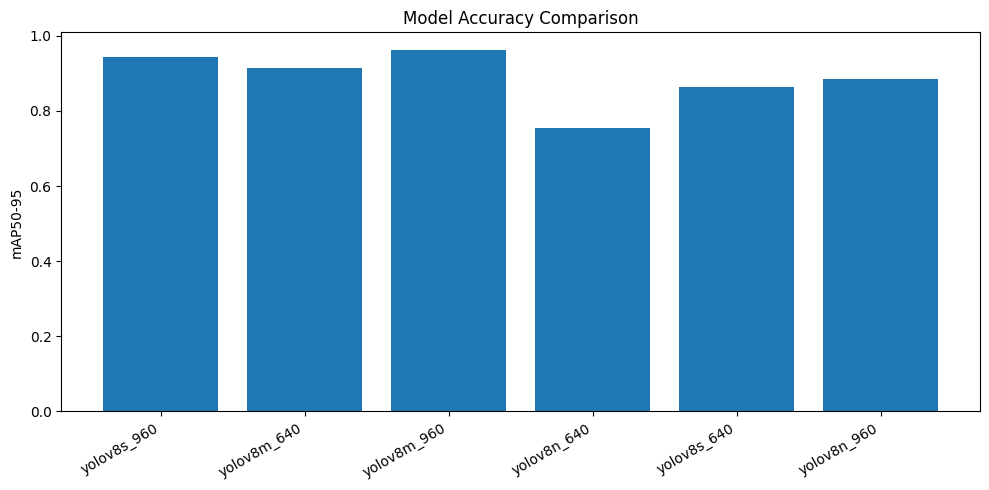

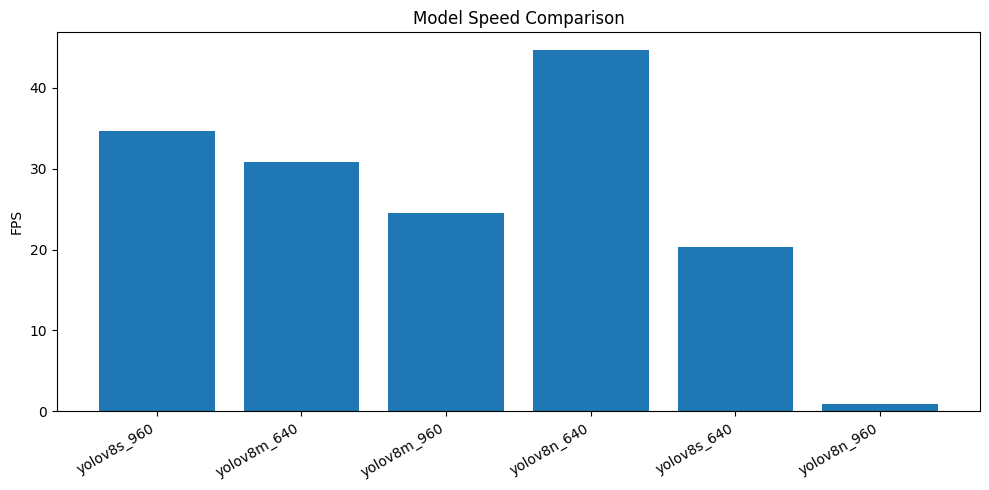

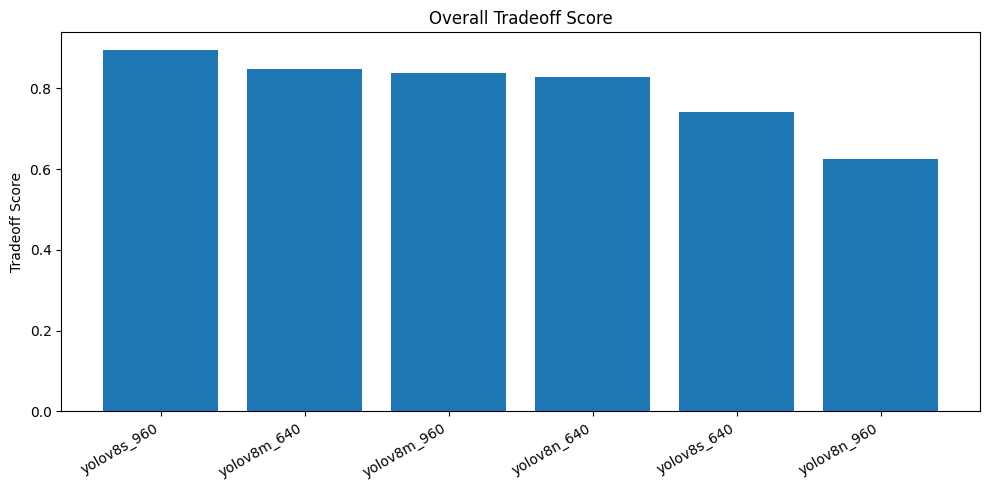

In [17]:
# Plot model comparison
plt.figure(figsize=(10, 5))
plt.bar(df_compare["model_name"], df_compare["mAP50_95"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("mAP50-95")
plt.title("Model Accuracy Comparison")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(df_compare["model_name"], df_compare["fps"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("FPS")
plt.title("Model Speed Comparison")
plt.tight_layout()
plt.show()

plt.figure(figsize=(10, 5))
plt.bar(df_compare["model_name"], df_compare["score"])
plt.xticks(rotation=30, ha="right")
plt.ylabel("Tradeoff Score")
plt.title("Overall Tradeoff Score")
plt.tight_layout()
plt.show()

In [18]:
# Run prediction using selected best model
best_model = YOLO(BEST_MODEL_PATH)

predictions = best_model.predict(
    source=str(VAL_IMG_DIR),
    imgsz=BEST_IMGSZ,
    conf=0.25,
    save=True,
    project=str(PREDICT_DIR),
    name="best_model_predictions",
    exist_ok=True,
    device=GPU_DEVICE,
    half=True,
    verbose=False
)

print("Prediction done using:", BEST_MODEL_NAME)
print("Saved predictions to:", PREDICT_DIR / "best_model_predictions")

Results saved to /workspace/predict/best_model_predictions
Prediction done using: yolov8s_960
Saved predictions to: /workspace/predict/best_model_predictions


Prediction images found: 1000


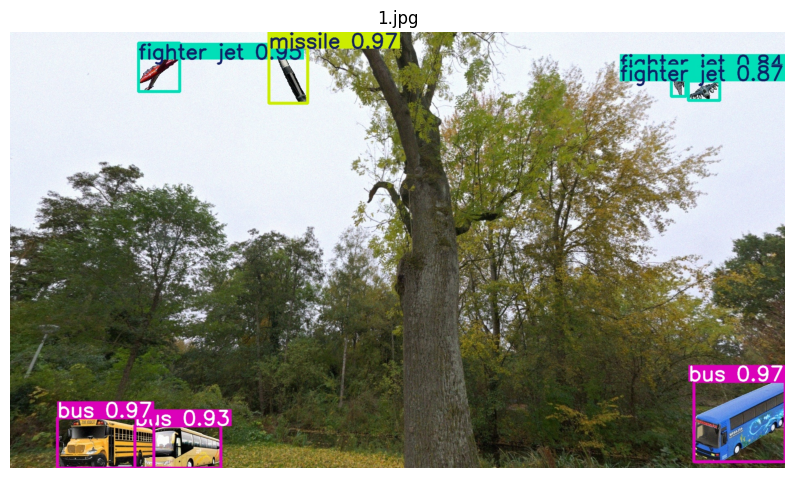

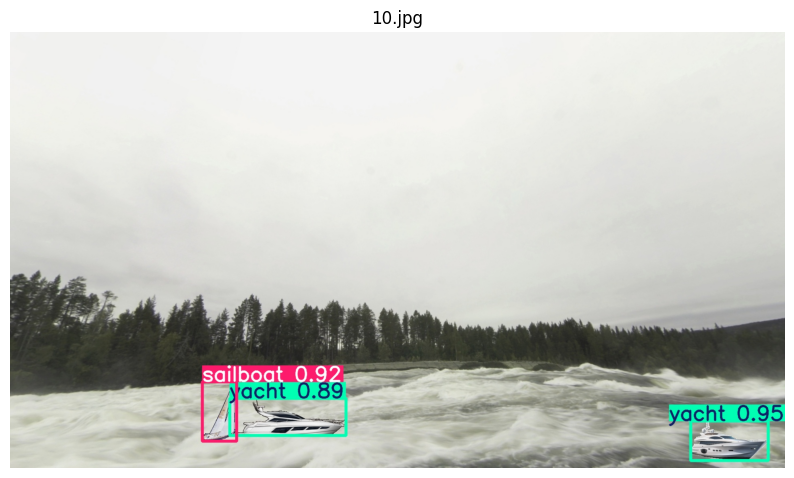

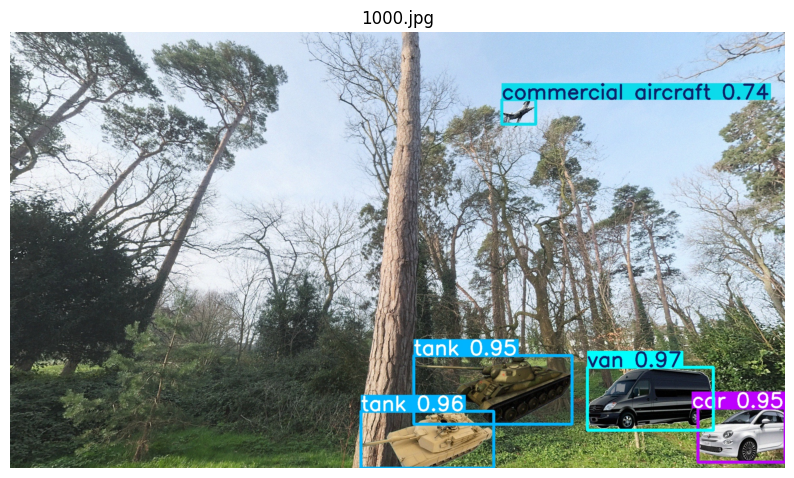

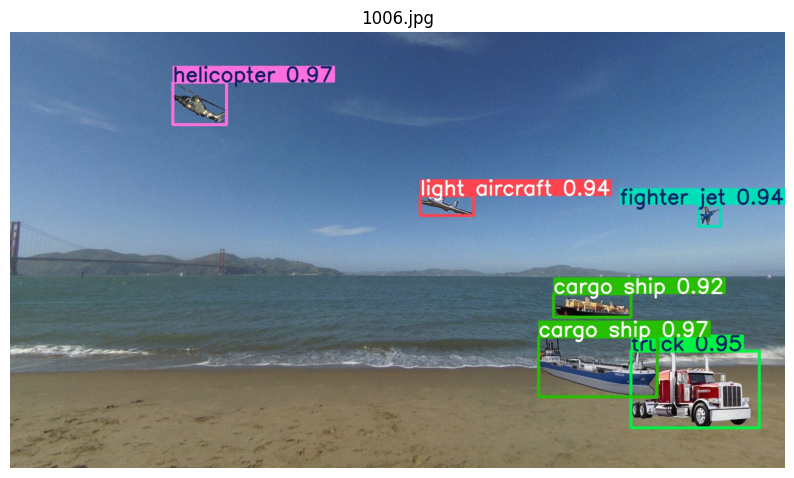

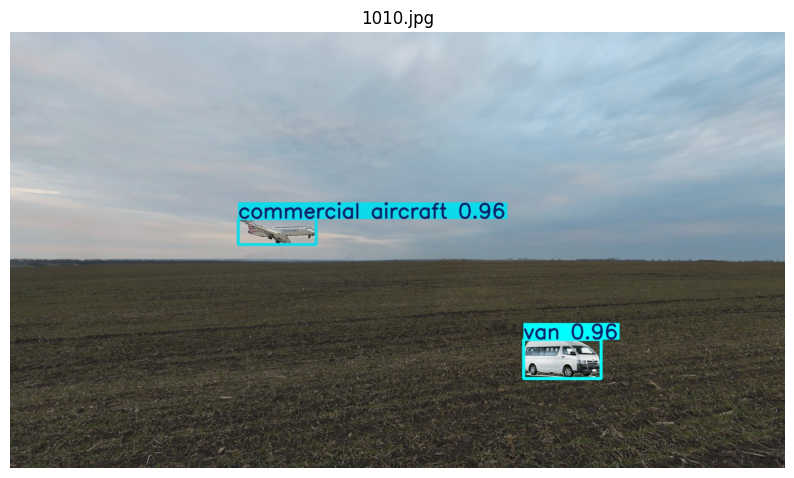

In [19]:
# Display sample prediction images
pred_folder = PREDICT_DIR / "best_model_predictions"
pred_images = sorted(list(pred_folder.glob("*.jpg")) + list(pred_folder.glob("*.png")) + list(pred_folder.glob("*.jpeg")))

print("Prediction images found:", len(pred_images))

for img_path in pred_images[:5]:
    img = Image.open(img_path)
    plt.figure(figsize=(10, 8))
    plt.imshow(img)
    plt.title(img_path.name)
    plt.axis("off")
    plt.show()

## Optional robustness test: noisy validation images

This is useful if the challenge images may have noise, brightness differences, or slight quality issues.

In [20]:
# Create noisy validation images
def add_noise(img, noise_std=6, brightness_scale=1.03, brightness_shift=2):
    img_float = img.astype(np.float32)
    noise = np.random.normal(0, noise_std, img.shape)
    noisy = img_float + noise
    noisy = noisy * brightness_scale + brightness_shift
    return np.clip(noisy, 0, 255).astype(np.uint8)

NOISY_VAL_DIR.mkdir(parents=True, exist_ok=True)

for img_path in tqdm(sorted(VAL_IMG_DIR.glob("*")), desc="Creating noisy val"):
    img = cv2.imread(str(img_path))
    if img is None:
        continue
    noisy = add_noise(img)
    cv2.imwrite(str(NOISY_VAL_DIR / img_path.name), noisy)

print("Noisy validation images:", len(list(NOISY_VAL_DIR.glob("*"))))

Creating noisy val:   0%|          | 0/1000 [00:00<?, ?it/s]

Noisy validation images: 1000


In [21]:
# Test selected model on noisy images
noisy_start = time.time()
noisy_results = best_model.predict(
    source=str(NOISY_VAL_DIR),
    imgsz=BEST_IMGSZ,
    conf=0.25,
    save=True,
    project=str(PREDICT_DIR),
    name="best_model_noisy_predictions",
    exist_ok=True,
    device=GPU_DEVICE,
    half=True,
    verbose=False
)
noisy_end = time.time()

noisy_count = len(list(NOISY_VAL_DIR.glob("*")))
noisy_fps = noisy_count / (noisy_end - noisy_start)

print("Noisy prediction FPS:", noisy_fps)
print("Saved noisy predictions to:", PREDICT_DIR / "best_model_noisy_predictions")

Results saved to /workspace/predict/best_model_noisy_predictions
Noisy prediction FPS: 10.343554868254696
Saved noisy predictions to: /workspace/predict/best_model_noisy_predictions


## Optional final export

Use this section to copy the final selected model to an easy-to-download path.

In [23]:
# Copy final best.pt to easy download path
final_model_output = Path("/workspace/predict/best_model_selected.pt")
shutil.copy2(BEST_MODEL_PATH, final_model_output)

print("Final selected model copied to:", final_model_output)
print("Use this file for deployment/submission if needed.")

Final selected model copied to: /workspace/predict/best_model_selected.pt
Use this file for deployment/submission if needed.
